# 3. Threshold and cost

A detector gives us a score. A maintenance team needs a yes or no: send someone out
or not. This notebook turns one into the other and picks the threshold that costs
least.

It does not need a real model. Everything here takes a series of scores indexed by
time, so we build one ourselves with spikes we put there on purpose. That lets us
check the functions give the right answer before any real model exists. When
notebooks 2 and 4 produce real scores, they go through exactly the same code.

The functions live in `util/evaluation.py`:

- `alarms(scores, threshold)` — when the score crosses the threshold, with repeated
  crossings merged into one alarm
- `evaluate(scores, failures, threshold)` — detections, misses, false alarms, and how
  long before each failure the first alarm came
- `total_cost(scores, failures, threshold, cost_false_alarm, cost_missed)`

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from util.evaluation import alarms, evaluate, total_cost

FIGURES = Path('../figures')
FIGURES.mkdir(exist_ok=True)

## Two rules the functions apply

**Merging.** A leak that keeps the score high for six hours would cross the
threshold at every 10-minute step, so one event would count as 36 alarms. After an
alarm, we ignore further crossings for a **refractory period** of 6 hours. If the
score is still high after that, a new alarm fires. That is deliberate: a technician
who has been out once and found nothing would be sent again.

**What counts as a warning.** An alarm counts as detecting a failure if it comes no
more than **2 days** before the failure starts, or during it. Earlier than that, we
cannot honestly claim it was about this failure. Any alarm outside every such window
is a false alarm.

Both are parameters (`refractory=`, `lead=`) and both are written up in
`DECISIONS.md`. The 2 days is provisional; it is the open question about how long
before a failure counts as anomalous.

## Checking the functions on a series we can work out by hand

Ten days of zeros, with four things added:

| what | when | height | expected |
|---|---|---|---|
| warning before failure A | day 2, 18:00–19:00 | 5 | one alarm, 6 h lead |
| failure B, weak signal | day 6, 02:00 | 2 | caught at threshold 1 (2 h late), missed at 3 |
| spurious spike | day 8, 12:00 | 5 | one false alarm |
| sustained excursion | all of day 9 | 5 | four false alarms, one per 6 h |

In [2]:
t0 = pd.Timestamp('2021-01-01')
day = lambda d, h=0: t0 + pd.Timedelta(days=d, hours=h)

toy = pd.Series(0.0, index=pd.date_range(t0, periods=10 * 144, freq='10min'))
toy[day(2, 18):day(2, 19)] = 5
toy[day(6, 2)] = 2
toy[day(8, 12)] = 5
toy[day(9):day(9, 23.9)] = 5

toy_failures = [(day(3), day(3, 6)), (day(6), day(6, 6))]

print(alarms(toy, 3))

DatetimeIndex(['2021-01-03 18:00:00', '2021-01-09 12:00:00',
               '2021-01-10 00:00:00', '2021-01-10 06:00:00',
               '2021-01-10 12:00:00', '2021-01-10 18:00:00'],
              dtype='datetime64[us]', freq=None)


In [3]:
r = evaluate(toy, toy_failures, threshold=3)
assert r['detected'] == 1 and r['missed'] == 1
assert r['false_alarms'] == 5          # day 8 once, day 9 four times
assert r['lead_times'].iloc[0] == pd.Timedelta(hours=6)
assert pd.isna(r['lead_times'].iloc[1])

r = evaluate(toy, toy_failures, threshold=1)
assert r['detected'] == 2 and r['missed'] == 0
assert r['lead_times'].iloc[1] == pd.Timedelta(hours=-2)   # negative = during the failure

assert total_cost(toy, toy_failures, 3, cost_false_alarm=1, cost_missed=20) == 5 * 1 + 1 * 20

# Same data, but an alarm 3 days early is too early to count:
assert evaluate(toy, [(day(5, 18), day(6))], 3)['detected'] == 0

print('all checks pass')

all checks pass


## A more realistic test series

Ninety days at 10-minute resolution and five failures. Before each one the score
climbs steadily over a day, then holds a plateau for the six hours the failure
lasts, the shape `DV_pressure` showed around F1–F3 in notebook 1. The failures
differ in how strongly they show, so a rising threshold loses them one at a time.

The noise is Student's t with 4 degrees of freedom rather than Gaussian. Real
anomaly scores have heavy tails: the occasional large value that is nothing at all.
With Gaussian noise, false alarms vanish so abruptly above about 4 that the choice
of threshold barely matters, which would make this notebook look easier than real
data will be.

We also add two spikes that belong to no failure, the stand-in for the mid-May
excursions in MetroPT-3 that nobody reported.

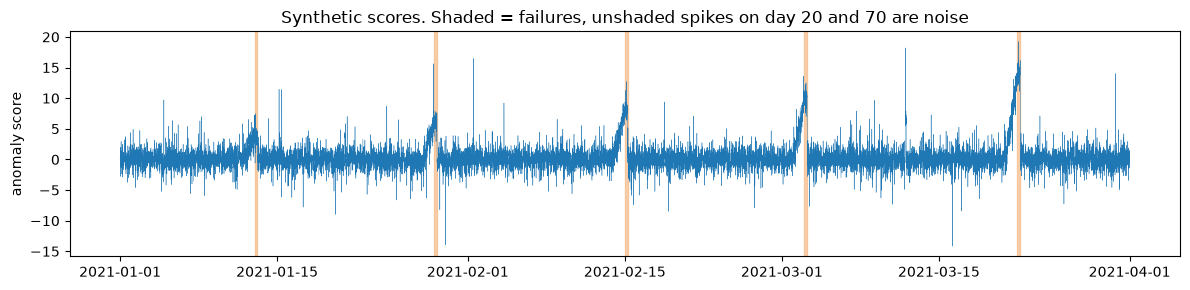

In [4]:
rng = np.random.default_rng(0)
index = pd.date_range('2021-01-01', periods=90 * 144, freq='10min')
scores = pd.Series(rng.standard_t(4, len(index)), index=index)

failures = []
for d, peak in [(12, 4), (28, 6), (45, 8), (61, 10), (80, 14)]:
    start = index[0] + pd.Timedelta(days=d)
    end = start + pd.Timedelta(hours=6)
    failures.append((start, end))

    ramp_from = start - pd.Timedelta(days=1)
    in_ramp = (index >= ramp_from) & (index < start)
    scores[in_ramp] += peak * np.asarray((index[in_ramp] - ramp_from) / (start - ramp_from))
    scores[start:end] += peak

for d, height in [(20, 4.0), (70, 6.0)]:
    start = index[0] + pd.Timedelta(days=d)
    scores[start:start + pd.Timedelta(hours=2)] += height


def mark_failures(ax, failures):
    for start, end in failures:
        ax.axvspan(start, end, color='sandybrown', alpha=0.5)


fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(scores.index, scores, lw=0.3, color='tab:blue')
mark_failures(ax, failures)
ax.set_ylabel('anomaly score')
ax.set_title('Synthetic scores. Shaded = failures, unshaded spikes on day 20 and 70 are noise')
plt.tight_layout()

## The cost numbers

We do not know what a technician costs Metro do Porto, so we pick something
reasonable and say why. Full reasoning is in `DECISIONS.md`. In short:

- **False alarm: 1 unit.** A technician inspects the train at the depot and finds
  nothing. A few hours of labour, the train possibly held back from one service.
- **Missed failure: 20 units.** The leak develops in service, the train is
  withdrawn unplanned, passengers are disrupted, and the compressor runs under
  strain until someone notices, which can turn a cheap repair into an expensive one.

Only the ratio matters for which threshold wins, so we work in units of one false
alarm and test other ratios below.

In [5]:
COST_FALSE_ALARM = 1
COST_MISSED = 20

thresholds = np.arange(2.0, 20.01, 0.1)
sweep = pd.DataFrame([evaluate(scores, failures, t) for t in thresholds], index=thresholds)
sweep['cost'] = sweep['false_alarms'] * COST_FALSE_ALARM + sweep['missed'] * COST_MISSED

# Sanity check: the sweep agrees with total_cost
assert sweep['cost'].iloc[60] == total_cost(scores, failures, thresholds[60], COST_FALSE_ALARM, COST_MISSED)

# If several thresholds tie for the lowest cost, take the lowest of them:
# a lower threshold alarms earlier and so gives more warning.
best = sweep.index[sweep['cost'] == sweep['cost'].min()].min()
sweep.loc[best, ['detected', 'missed', 'false_alarms', 'cost']]

detected         5
missed           0
false_alarms    10
cost            10
Name: 7.300000000000004, dtype: int64

## Total cost against threshold

This is the plot that goes on the slides.

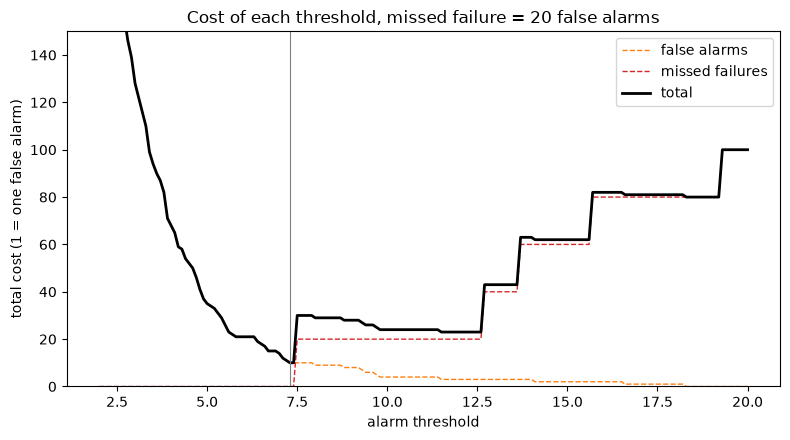

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(sweep.index, sweep['false_alarms'] * COST_FALSE_ALARM,
        color='tab:orange', lw=1, ls='--', label='false alarms')
ax.plot(sweep.index, sweep['missed'] * COST_MISSED,
        color='tab:red', lw=1, ls='--', label='missed failures')
ax.plot(sweep.index, sweep['cost'], color='black', lw=2, label='total')
ax.axvline(best, color='grey', lw=0.8)
ax.annotate(f'chosen: {best:.1f}', (best, sweep['cost'].max() * 0.9),
            xytext=(5, 0), textcoords='offset points', fontsize=9)

ax.set_ylim(0, 150)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('total cost (1 = one false alarm)')
ax.set_title(f'Cost of each threshold, missed failure = {COST_MISSED} false alarms')
ax.legend()
plt.tight_layout()
fig.savefig(FIGURES / 'cost_vs_threshold.png', dpi=200)

Too low and the noise sets off alarm after alarm. Too high and the failures go
unnoticed, each one a step up of 20. The bottom is where all five are caught with
as few false alarms as that allows.

**The U is lopsided, and that matters.** To the left of the minimum the cost rises
slowly, one false alarm at a time. To the right it jumps by a whole missed failure
the moment the weakest one slips under. The minimum sits right at that edge: at
7.3 the first failure is caught, at 7.4 it is not. On real data, where the next
leak will not look exactly like the last, we should set the threshold somewhat
**below** the minimum, not at it. Erring low costs a few false alarms; erring high
costs a failure.

## How much warning do we get?

A detection two hours before the failure is worth far more than one two minutes
before: the first can be fixed at the depot overnight, the second cannot. The cost
model above does not see this, so we look at it separately.

2021-01-13 00:00:00    -2.3
2021-01-29 00:00:00     2.0
2021-02-15 00:00:00     5.8
2021-03-03 00:00:00    16.2
2021-03-22 00:00:00    13.0
Name: hours of warning at chosen threshold, dtype: float64

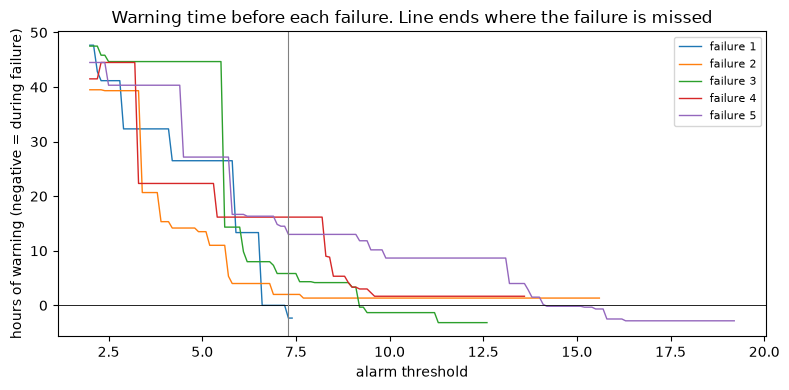

In [7]:
hours = pd.DataFrame([lt.dt.total_seconds() / 3600 for lt in sweep['lead_times']],
                     index=sweep.index)

fig, ax = plt.subplots(figsize=(8, 4))
for i, col in enumerate(hours.columns):
    ax.plot(hours.index, hours[col], lw=1, label=f'failure {i + 1}')
ax.axhline(0, color='black', lw=0.6)
ax.axvline(best, color='grey', lw=0.8)
ax.set_xlabel('alarm threshold')
ax.set_ylabel('hours of warning (negative = during failure)')
ax.set_title('Warning time before each failure. Line ends where the failure is missed')
ax.legend(fontsize=8)
plt.tight_layout()

hours.loc[best].round(1).rename('hours of warning at chosen threshold')

Raising the threshold always costs warning time, even while it still catches the
failure. Weak failures suffer most: the first one is only caught once it has
already started. That is a second reason to err low.

## What if the cost ratio is different?

The 1 : 20 ratio is a guess. Here is how the choice moves if a missed failure is
worth 5, 20 or 100 false alarms.

,threshold,detected,false alarms
missed costs,,,
5,11.5,4,3
20,7.3,5,10
100,7.3,5,10


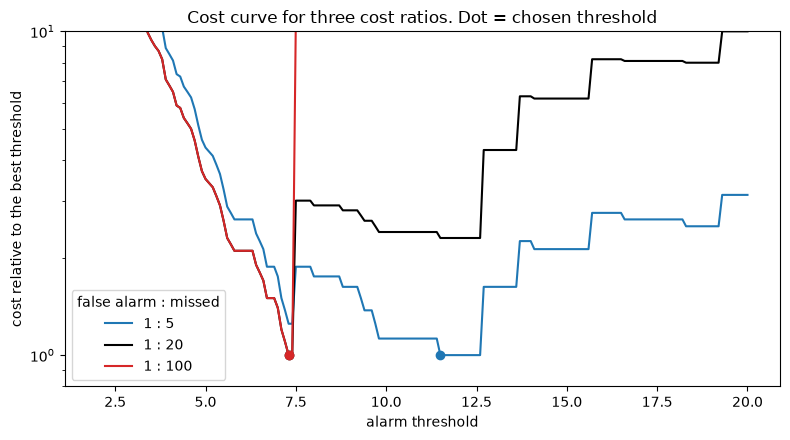

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))

rows = []
for ratio, colour in [(5, 'tab:blue'), (20, 'black'), (100, 'tab:red')]:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen = cost.index[cost == cost.min()].min()
    ax.plot(cost.index, cost / cost.min(), color=colour, lw=1.5, label=f'1 : {ratio}')
    ax.plot(chosen, 1, 'o', color=colour)
    r = sweep.loc[chosen]
    rows.append({'missed costs': ratio, 'threshold': round(chosen, 1),
                 'detected': r['detected'], 'false alarms': r['false_alarms']})

ax.set_ylim(0.8, 10)
ax.set_yscale('log')
ax.set_xlabel('alarm threshold')
ax.set_ylabel('cost relative to the best threshold')
ax.set_title('Cost curve for three cost ratios. Dot = chosen threshold')
ax.legend(title='false alarm : missed')
plt.tight_layout()
fig.savefig(FIGURES / 'cost_ratio_sensitivity.png', dpi=200)

pd.DataFrame(rows).set_index('missed costs')

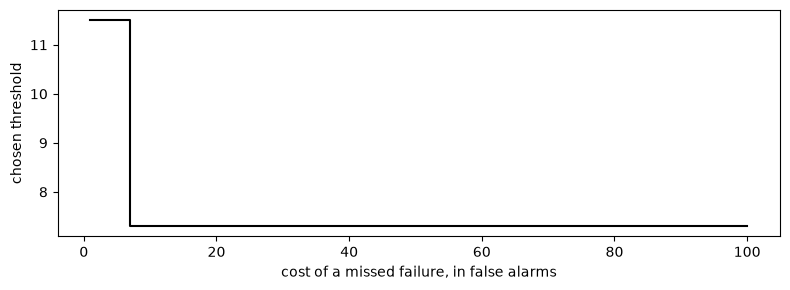

In [9]:
# Over a fine grid of ratios: where does the chosen threshold move?
ratios = np.arange(1, 101)
chosen = []
for ratio in ratios:
    cost = sweep['false_alarms'] + sweep['missed'] * ratio
    chosen.append(cost.index[cost == cost.min()].min())

fig, ax = plt.subplots(figsize=(8, 3))
ax.step(ratios, chosen, where='post', color='black')
ax.set_xlabel('cost of a missed failure, in false alarms')
ax.set_ylabel('chosen threshold')
plt.tight_layout()

## What we learned

**The functions do what we meant.** The hand-built series gives exactly the counts
and lead times we worked out in advance, including the merging of a sustained
excursion and the 2-day cut-off.

**The cost curve has the expected U-shape**, and the threshold at its bottom is our
choice. At 1 : 20 it catches all five failures for 10 false alarms over 90 days.

**It is lopsided.** Cost rises slowly below the minimum and jumps above it, so on
real data we should pick a threshold a little below the minimum rather than at it.

**The cost ratio decides one thing: whether to chase the weakest failure.**
Catching it costs about 7 extra false alarms. If a miss is worth more than that,
the threshold drops from 11.5 to 7.3; if less, we let it go. Between 1 : 20 and
1 : 100 nothing changes, so the exact figure matters less than whether a miss is
"a few" or "many" false alarms. On real data, this is the plot to check first.

**Lead time is a separate thing from cost.** The simple cost model treats a
detection two minutes before failure the same as one a day before. Lead time
against threshold is the plot that shows what we give up by raising the threshold.

## Using it on real scores

```python
from util.evaluation import evaluate, total_cost
evaluate(kde_scores, failures, threshold)
```

`failures` is the same list of (start, end) pairs as in notebook 1. Nothing in
`util/evaluation.py` assumes anything about the scores except that higher means
more anomalous.